# Estudio de caso — Turbomáquinas
**Universidad Metropolitana** · Departamento de Energía y Automatización · Trimestre 2627-1
**Profesor:** Juan Tasco · **Autores:** Héctor Villalobos y Luis Tinoco

Selección y dimensionamiento de una turbina de vapor comercial (Siemens SST-110) para un ciclo Rankine de 3.5 MW netos.

## 1. Planteamiento del problema y objetivos

Se trata de un problema de **generación de energía**. Una planta de vapor debe entregar
$\dot W_{neto} = 3.5\ \mathrm{MW}$ con un ciclo Rankine simple: el vapor sale de la caldera a
$35\ \mathrm{bar}$ y $420\ ^\circ\mathrm{C}$, se expande en una turbina y se condensa a $15\ \mathrm{kPa}$.
La bomba de alimentación tiene una eficiencia isentrópica $\eta_b = 0.80$.

La eficiencia de la turbina no se conoce hasta que se selecciona y se dimensiona. Por eso el estudio
sigue tres pasos: un ciclo preliminar con $\eta_t$ estimada, el diseño de la turbina con la teoría de
turbomáquinas térmicas y el recálculo del ciclo con la eficiencia que resulta del diseño.

**Objetivo general.** Seleccionar una turbina de vapor comercial para el ciclo y dimensionarla etapa por etapa.

**Objetivos específicos.**
1. Calcular todos los estados del ciclo preliminar con una ecuación de estado de referencia para el agua.
2. Determinar el número de etapas, los triángulos de velocidades, la geometría de álabes y la eficiencia
   de la turbina, respetando los criterios de carga, caudal, Mach, altura de álabe y título de vapor.
3. Recalcular el ciclo con la eficiencia de la turbina diseñada hasta que ciclo y turbina sean consistentes.
4. Verificar que el punto de operación cae dentro de la envolvente de catálogo de la Siemens SST-110.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from CoolProp.CoolProp import PropsSI
from IPython.display import Markdown, Math, display

from ciclo import calcular_ciclo, tabla_comparacion, tabla_desempeno, tabla_estados
from datos import (CATALOGO_SST110, CRITERIOS, DATOS_CICLO, DISENO_ORIGINAL,
                   ETA_ALABE_ORIGINAL, ETA_TURBINA_INICIAL)
from graficas import (configurar_estilo, figura_ciclo, figura_etapas, figura_expansion_hs,
                      figura_triangulos)
from turbina import (cerrar_lazo, evaluar_turbina, grado_reaccion, tabla_resumen_diseno,
                     verificar_catalogo, verificar_criterios)

%matplotlib inline
configurar_estilo()
pd.set_option('display.precision', 3)

## 2. Ecuación de estado

Las propiedades del agua se calculan con **CoolProp**, cuyo backend por defecto para `Water` es la
formulación **IAPWS-95** (Wagner y Pruß), una ecuación de estado explícita en la energía de Helmholtz:

$$\frac{a(\rho, T)}{R\,T} = \phi^{\circ}(\delta, \tau) + \phi^{r}(\delta, \tau), \qquad \delta = \frac{\rho}{\rho_c},\quad \tau = \frac{T_c}{T}$$

No se usa $c_p$ constante ni el modelo de gas ideal, porque el vapor cambia de fase dentro de la turbina.
Como contraste, se compara con la formulación industrial **IAPWS-IF97**, la de las tablas de vapor habituales, en dos estados del ciclo:

In [2]:
puntos = {'Líquido saturado a 15 kPa': ('P', 15e3, 'Q', 0),
          'Vapor a 35 bar y 420 °C': ('P', 35e5, 'T', 420 + 273.15)}
filas = []
for nombre, (a, valor_a, b, valor_b) in puntos.items():
    h_95 = PropsSI('H', a, valor_a, b, valor_b, 'Water') / 1e3
    h_97 = PropsSI('H', a, valor_a, b, valor_b, 'IF97::Water') / 1e3
    filas.append((nombre, h_95, h_97, h_95 - h_97))
pd.DataFrame(filas, columns=['Estado', 'h IAPWS-95 [kJ/kg]', 'h IAPWS-IF97 [kJ/kg]',
                             'Diferencia [kJ/kg]']).set_index('Estado').round(3)

,h IAPWS-95 [kJ/kg],h IAPWS-IF97 [kJ/kg],Diferencia [kJ/kg]
Estado,,,
Líquido saturado a 15 kPa,225.944,225.935,0.009
Vapor a 35 bar y 420 °C,3269.367,3269.219,0.148


## 3. Ciclo Rankine preliminar

### 3.1 Planteamiento matemático

| Estado | Condición | Cálculo |
|---|---|---|
| 1 | Líquido saturado a $P_1$ | $h_1 = h_f(P_1)$, $\; s_1 = s_f(P_1)$ |
| 2 | Salida de bomba | $h_{2s} = h(P_2, s_1)$, $\; h_2 = h_1 + \dfrac{h_{2s} - h_1}{\eta_b}$ |
| 3 | Salida de caldera | $h_3 = h(P_3, T_3)$, $\; s_3 = s(P_3, T_3)$ |
| 4 | Salida de turbina | $h_{4s} = h(P_4, s_3)$, $\; h_4 = h_3 - \eta_t\,(h_3 - h_{4s})$ |

$$w_b = h_2 - h_1, \qquad w_t = h_3 - h_4, \qquad w_{neto} = w_t - w_b, \qquad q_{in} = h_3 - h_2$$

$$\eta_{th} = \frac{w_{neto}}{q_{in}}, \qquad \dot m = \frac{\dot W_{neto}}{w_{neto}}$$

En esta primera pasada se supone $\eta_t = 0.82$.

In [3]:
ciclo_preliminar = calcular_ciclo(DATOS_CICLO, ETA_TURBINA_INICIAL)
tabla_estados(ciclo_preliminar['estados']).round(4)

,P [kPa],T [°C],h [kJ/kg],s [kJ/(kg·K)],ρ [kg/m³],x [-]
1,15.0,53.969,225.944,0.755,986.151,0.000
2s,3500.0,54.103,229.476,0.755,987.602,NaN
2,3500.0,54.315,230.358,0.758,987.501,NaN
3,3500.0,420.000,3269.367,6.910,11.421,NaN
4s,15.0,53.969,2239.538,6.910,0.118,0.849
4,15.0,53.969,2424.907,7.477,0.108,0.927


In [4]:
tabla_desempeno(ciclo_preliminar['desempeno']).round(2)

,Valor,Unidad
Magnitud,,
Salto entálpico isentrópico de turbina,1029.83,kJ/kg
Trabajo real de turbina,844.46,kJ/kg
Trabajo de bomba,4.41,kJ/kg
Trabajo neto,840.05,kJ/kg
Calor añadido en caldera,3039.01,kJ/kg
Calor rechazado en condensador,2198.96,kJ/kg
Eficiencia térmica,27.64,%
Caudal másico de vapor,4.17,kg/s
Potencia de turbina,3518.39,kW


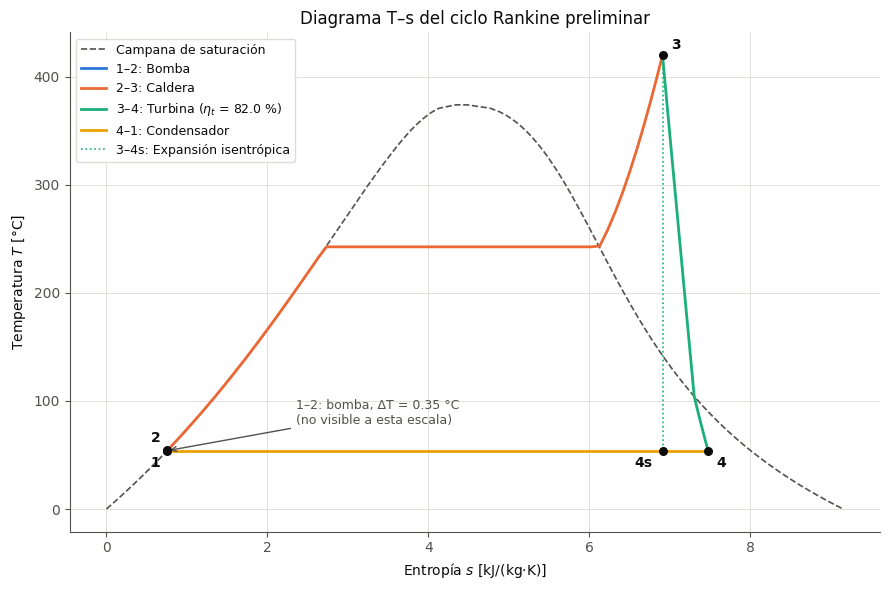

In [5]:
fig = figura_ciclo(ciclo_preliminar, 'Diagrama T–s del ciclo Rankine preliminar')
fig.savefig('diagrama_Ts_rankine.png')
plt.show()

## 4. Selección de la turbomáquina

### 4.1 Equipo comercial: Siemens SST-110

La SST-110 es una turbina industrial de vapor de **doble carcasa**. Su envolvente de catálogo admite
vapor de hasta $131\ \mathrm{bar}$ y $530\ ^\circ\mathrm{C}$, lo que cubre el punto de diseño
($35\ \mathrm{bar}$, $420\ ^\circ\mathrm{C}$). La velocidad máxima y la presión mínima de escape usadas
abajo **deben confirmarse con el datasheet**. El diámetro medio, el número de etapas y la velocidad de giro
**no son datos de catálogo**: son el resultado del dimensionamiento preliminar de línea media de este estudio.

### 4.2 Teoría: etapa axial de reacción 50 %

Ángulos medidos desde la dirección axial, con $c_m$ constante.

**Ecuación de Euler y condición de simetría** ($R = 0.5$):

$$w = u\,(c_{\theta 2} - c_{\theta 3}), \qquad c_{\theta 2} + c_{\theta 3} = u \;\;\Longrightarrow\;\; c_{\theta 2} = \frac{w + u^2}{2u}, \quad c_{\theta 3} = u - c_{\theta 2}$$

**Velocidades relativas y ángulos:**

$$w_{\theta} = c_{\theta} - u, \qquad \tan\alpha = \frac{c_\theta}{c_m}, \qquad \tan\beta = \frac{w_\theta}{c_m}$$

En una etapa *repetida* (de la 2 en adelante) el vapor entra con el ángulo con que salió de la anterior:
$\alpha_1 = \alpha_3$. Solo la primera etapa tiene entrada axial ($\alpha_1 = 0$).

**Coeficientes adimensionales y grado de reacción.** $R$ se verifica con las velocidades relativas, una fórmula
que no usa la condición de simetría con la que se construyeron los triángulos:

$$\psi = \frac{w}{u^2}, \qquad \phi = \frac{c_m}{u}, \qquad R = \frac{w_3^2 - w_2^2}{2\,w}$$

**Pérdidas (modelo de eficiencia de álabe) y humedad (regla de Baumann):**

$$\Delta h_{p,N} = (1 - \eta_{al})\,\frac{c_2^2 - c_1^2}{2}, \qquad \Delta h_{p,R} = (1 - \eta_{al})\,\frac{w_3^2 - w_2^2}{2}$$

$$\eta_{etapa} = \frac{w}{w + \Delta h_{p,N} + \Delta h_{p,R}}\,\left(1 - \bar y\right), \qquad \bar y = \text{humedad media de la etapa}$$

**Eficiencia de la turbina.** Con trabajo igual por etapa, se toma la media armónica de las etapas.
Se desprecia el factor de recalentamiento, lo que es conservador:

$$\eta_t = f_{fugas}\,\frac{Z}{\sum_{i=1}^{Z} 1/\eta_i}$$

**Geometría.** La altura de álabe se calcula con la densidad a la salida de cada etapa. Si $h < h_{min} = 10\ \mathrm{mm}$,
la teoría de cascadas 2D deja de aplicar y se usa **admisión parcial** $\varepsilon$:

$$h_{teo} = \frac{\dot m}{\rho\, c_m\, \pi D_m}, \qquad \varepsilon = \min\!\left(1, \frac{h_{teo}}{h_{min}}\right), \qquad c = \frac{h}{AR}, \qquad s = \frac{c}{\sigma}, \qquad z = \frac{\pi D_m}{s}$$

$z_{toberas}$ y $z_{rotor}$ se eligen primos entre sí para evitar resonancias.

**Mach.** $M = \max(c_2, w_3)/a$. En vapor sobrecalentado $a$ sale de IAPWS-95. En vapor húmedo se usa
$a \approx \sqrt{k\,p\,v}$ con el exponente de Zeuner $k = 1.035 + 0.1\,x$.

**Línea de expansión.** Recta $3 \to 4$ en el diagrama $h$–$s$, dividida en $Z$ etapas de igual trabajo.

### 4.3 Diagnóstico del diseño preliminar anterior

La primera versión del trabajo usaba 6 etapas, $D_m = 0.52\ \mathrm{m}$, $N = 11\,500\ \mathrm{rpm}$,
$\phi = 0.65$ y $\eta_{al} = 0.87$. Solo revisaba la última etapa, con una densidad fija
$\rho = 0.22\ \mathrm{kg/m^3}$. Aquí ese mismo diseño se evalúa **etapa por etapa**:

In [6]:
diseno_original = evaluar_turbina(ciclo_preliminar, DISENO_ORIGINAL,
                                 {**CRITERIOS, 'eta_alabe': ETA_ALABE_ORIGINAL})
columnas = ['P_salida [kPa]', 'x_salida', 'rho_salida [kg/m³]', 'Mach', 'h_teorica [mm]', 'admision']
diseno_original['tabla'][columnas].round(3)

,P_salida [kPa],x_salida,rho_salida [kg/m³],Mach,h_teorica [mm],admision
etapa,,,,,,
1,1743.645,NaN,6.334,0.725,1.978,0.198
2,820.277,NaN,3.372,0.768,3.717,0.372
3,357.461,NaN,1.698,0.824,7.379,0.738
4,140.110,NaN,0.792,0.896,15.830,1.000
5,48.430,0.966,0.310,1.028,40.415,1.000
6,15.000,0.927,0.108,1.090,116.390,1.000


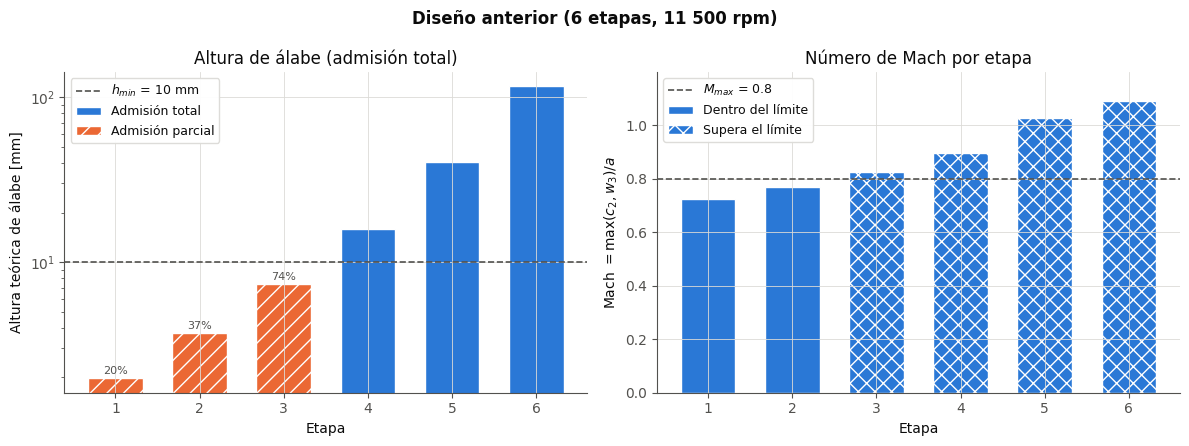

,Criterio,Valor,Límite,Cumple
0,Título a la salida x₄,0.927,≥ 0.88,True
1,Coeficiente de carga ψ,1.436,0.8 – 1.5,True
2,Mach máximo,1.090,< 0.8,False
3,Altura de álabe mínima [mm],10.000,≥ 10,True
4,h/D última etapa,0.224,≤ 0.3,True
5,Grado de reacción R,0.500,0.50,True
6,Etapas con admisión parcial,3.000,informativo,—
7,Admisión parcial mínima,0.198,informativo (típico ≈ 0.25),—


In [7]:
fig = figura_etapas(diseno_original['tabla'], CRITERIOS, 'Diseño anterior (6 etapas, 11 500 rpm)')
fig.savefig('etapas_diseno_original.png')
plt.show()
verificar_criterios(ciclo_preliminar, diseno_original, CRITERIOS)

**Problemas detectados:**

- **Mach > 0.8 en las etapas de baja presión.** Las seis etapas comparten los triángulos
  ($c_2 = w_3 \approx 432\ \mathrm{m/s}$), pero la velocidad del sonido cae a unos $400\ \mathrm{m/s}$ en el vapor húmedo.
  El criterio de diseño exige $M < 0.8$ en **todas** las etapas para evitar ondas de choque.
- **Álabes de alta presión de unos 2 mm.** La densidad baja unas 100 veces entre la entrada y la salida,
  y con un diámetro fijo los primeros álabes quedan muy por debajo de $10\ \mathrm{mm}$.
- **La densidad fija de 0.22 kg/m³ no corresponde a la salida.** La densidad real a la salida es
  $\approx 0.108\ \mathrm{kg/m^3}$, así que el último álabe mide unos 116 mm y no 57 mm.

### 4.4 Diseño por restricciones

En lugar de fijar $N$ y $D_m$ a mano, se despejan de los criterios. En una etapa simétrica,
$c_2/u = \sqrt{\phi^2 + \left(\tfrac{1+\psi}{2}\right)^2}$, y la condición más exigente de Mach está a la salida
(estado 4, menor $a$):

$$u = \frac{M_{max}\; a_4}{\sqrt{\phi^2 + \left(\dfrac{1 + \psi_{max}}{2}\right)^2}}, \qquad
Z = \left\lceil \frac{w_t}{\psi_{max}\, u^2} \right\rceil$$

El diámetro medio se elige para que la última etapa respete $h/D_m \le 0.3$ (validez del análisis de línea media):

$$D_m = \sqrt{\frac{\dot m}{(h/D)_{max}\;\rho_4\,\phi\,u\,\pi}}, \qquad N = \frac{60\,u}{\pi D_m}$$

Criterios de diseño usados:

In [8]:
pd.Series(CRITERIOS, name='Valor').to_frame()

,Valor
phi,0.50
psi_max,1.40
mach_max,0.80
h_min,0.01
h_sobre_D_max,0.30
x_min,0.88
eta_alabe,0.92
factor_fugas,0.96
relacion_aspecto,2.00
solidez,1.50


## 5. Recálculo del ciclo: lazo ciclo ↔ turbina

El diseño depende de $\eta_t$, porque $w_t$, $\dot m$ y el estado 4 cambian con ella. A su vez, $\eta_t$ depende
del diseño. Por eso se itera hasta que $|\eta_t^{(k+1)} - \eta_t^{(k)}| < 10^{-5}$:

$$\eta_t^{(k)} \;\rightarrow\; \text{ciclo} \;\rightarrow\; (u,\, Z,\, D_m,\, N) \;\rightarrow\; \text{etapas} \;\rightarrow\; \eta_t^{(k+1)}$$

In [9]:
resultado = cerrar_lazo(DATOS_CICLO, CRITERIOS, ETA_TURBINA_INICIAL)
ciclo_final, diseno, turbina = resultado['ciclo'], resultado['diseno'], resultado['turbina']
print('Convergió:', resultado['convergio'])
resultado['historial'].round(4)

Convergió: True


,η_t supuesta,η_t calculada,Z,N [rpm],D [m],ṁ [kg/s]
iteración,,,,,,
1,0.820,0.878,11,8028.782,0.580,4.166
2,0.878,0.871,12,8239.252,0.557,3.889
3,0.871,0.872,12,8214.381,0.560,3.921
4,0.872,0.872,12,8217.727,0.559,3.917
5,0.872,0.872,12,8217.280,0.559,3.917
6,0.872,0.872,12,8217.340,0.559,3.917


In [10]:
tabla_resumen_diseno(diseno, turbina).round(4)

,Valor,Unidad
Parámetro,,
Número de etapas Z,12.000,—
Velocidad de giro N,8217.340,rpm
Diámetro medio D_m,0.559,m
Velocidad periférica u,240.693,m/s
Trabajo por etapa w,74.830,kJ/kg
Coeficiente de carga ψ,1.292,—
Coeficiente de caudal φ,0.500,—
Eficiencia de la turbina η_t,0.872,—


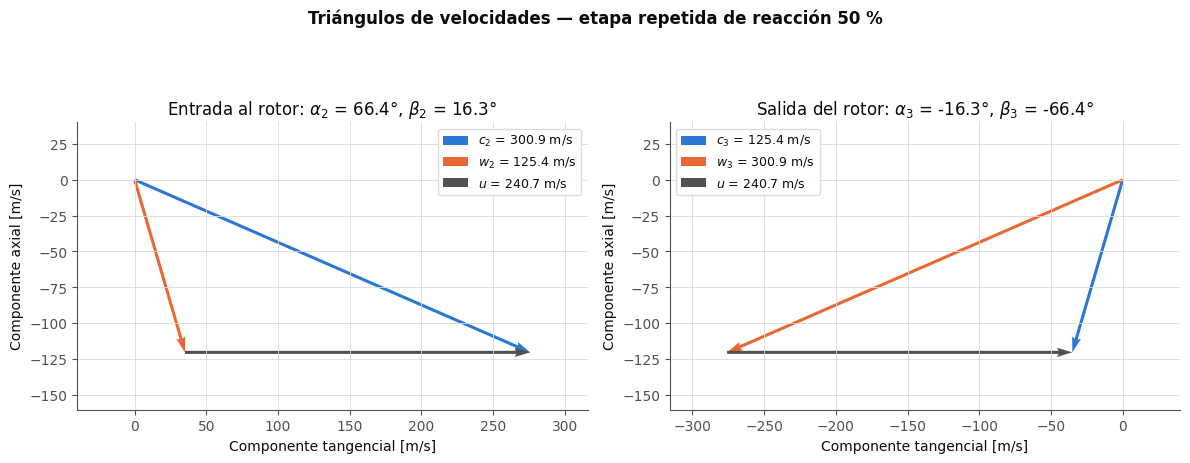

<IPython.core.display.Math object>

In [11]:
fig = figura_triangulos(turbina['triangulos'], 'Triángulos de velocidades — etapa repetida de reacción 50 %')
fig.savefig('triangulos_turbina.png')
plt.show()
t = turbina['triangulos']
display(Math(rf"\alpha_2 = {t['alpha2']:.2f}^\circ,\quad \beta_2 = {t['beta2']:.2f}^\circ,\quad "
             rf"\alpha_3 = {t['alpha3']:.2f}^\circ,\quad \beta_3 = {t['beta3']:.2f}^\circ,\quad "
             rf"R = {grado_reaccion(t):.3f}"))

In [12]:
turbina['tabla'].round(3)

,P_salida [kPa],x_salida,rho_salida [kg/m³],Mach,eta_etapa,h_teorica [mm],admision,h [mm],h/D,cuerda [mm],AR,z_toberas,z_rotor
etapa,,,,,,,,,,,,,
1,2524.228,NaN,8.707,0.492,0.925,2.127,0.213,10.000,0.018,20.000,0.500,28,135
2,1794.236,NaN,6.567,0.506,0.926,2.820,0.282,10.000,0.018,20.000,0.500,37,132
3,1254.301,NaN,4.895,0.522,0.926,3.784,0.378,10.000,0.018,20.000,0.500,50,133
4,860.140,NaN,3.597,0.540,0.926,5.148,0.515,10.000,0.018,20.000,0.500,68,133
5,576.744,NaN,2.601,0.559,0.926,7.120,0.712,10.000,0.018,20.000,0.500,94,133
6,376.603,NaN,1.844,0.582,0.926,10.041,1.000,10.041,0.018,20.000,0.502,132,133
7,238.244,NaN,1.278,0.609,0.926,14.494,1.000,14.494,0.026,20.000,0.725,132,133
8,145.266,0.991,0.845,0.682,0.922,21.916,1.000,21.916,0.039,20.000,1.096,132,133
9,86.066,0.968,0.530,0.702,0.907,34.946,1.000,34.946,0.062,20.000,1.747,132,133


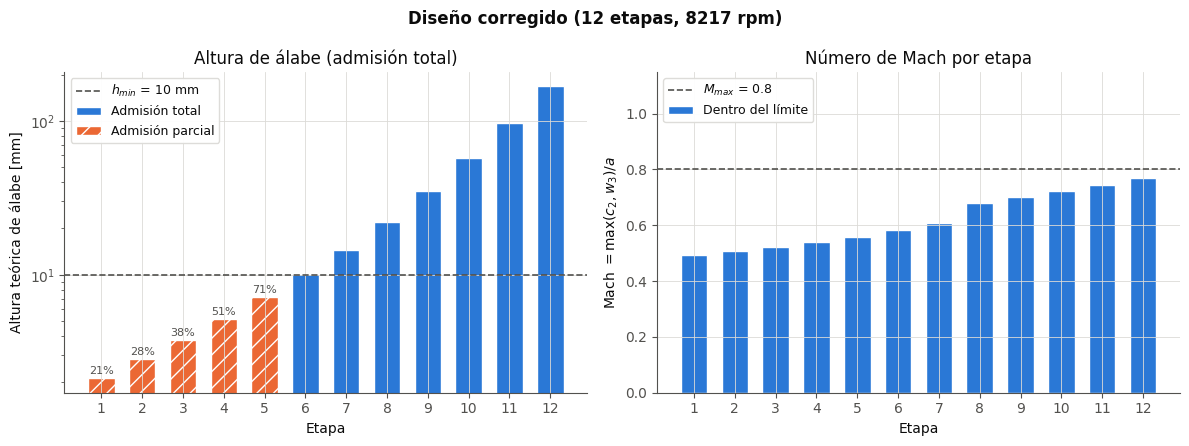

In [13]:
fig = figura_etapas(turbina['tabla'], CRITERIOS,
                    f"Diseño corregido ({diseno['etapas']} etapas, {diseno['N_rpm']:.0f} rpm)")
fig.savefig('etapas_diseno_corregido.png')
plt.show()

### 5.1 Verificación de criterios y de la envolvente de catálogo

In [14]:
verificar_criterios(ciclo_final, turbina, CRITERIOS)

,Criterio,Valor,Límite,Cumple
0,Título a la salida x₄,0.904,≥ 0.88,True
1,Coeficiente de carga ψ,1.292,0.8 – 1.5,True
2,Mach máximo,0.769,< 0.8,True
3,Altura de álabe mínima [mm],10.000,≥ 10,True
4,h/D última etapa,0.300,≤ 0.3,True
5,Grado de reacción R,0.500,0.50,True
6,Etapas con admisión parcial,5.000,informativo,—
7,Admisión parcial mínima,0.213,informativo (típico ≈ 0.25),—


In [15]:
verificar_catalogo(ciclo_final, diseno, CATALOGO_SST110)

,Condición,Diseño,Límite de catálogo,Cumple
0,Presión de admisión [bar],35.00,131.000,True
1,Temperatura de admisión [°C],420.00,530.000,True
2,Presión de escape [bar] (mínimo),0.15,0.035,True
3,Velocidad de giro [rpm],8217.34,13200.000,True


### 5.2 Ciclo recalculado

In [16]:
tabla_estados(ciclo_final['estados']).round(4)

,P [kPa],T [°C],h [kJ/kg],s [kJ/(kg·K)],ρ [kg/m³],x [-]
1,15.0,53.969,225.944,0.755,986.151,0.000
2s,3500.0,54.103,229.476,0.755,987.602,NaN
2,3500.0,54.315,230.358,0.758,987.501,NaN
3,3500.0,420.000,3269.367,6.910,11.421,NaN
4s,15.0,53.969,2239.538,6.910,0.118,0.849
4,15.0,53.969,2371.404,7.314,0.110,0.904


In [17]:
tabla_comparacion(ciclo_preliminar, ciclo_final).round(3)

,Preliminar,Recalculado,Cambio,Unidad
Magnitud,,,,
Salto entálpico isentrópico de turbina,1029.829,1029.829,0.000,kJ/kg
Trabajo real de turbina,844.460,897.963,53.503,kJ/kg
Trabajo de bomba,4.414,4.414,0.000,kJ/kg
Trabajo neto,840.046,893.549,53.503,kJ/kg
Calor añadido en caldera,3039.009,3039.009,0.000,kJ/kg
Calor rechazado en condensador,2198.963,2145.460,-53.503,kJ/kg
Eficiencia térmica,27.642,29.403,1.761,%
Caudal másico de vapor,4.166,3.917,-0.249,kg/s
Potencia de turbina,3518.391,3517.290,-1.101,kW


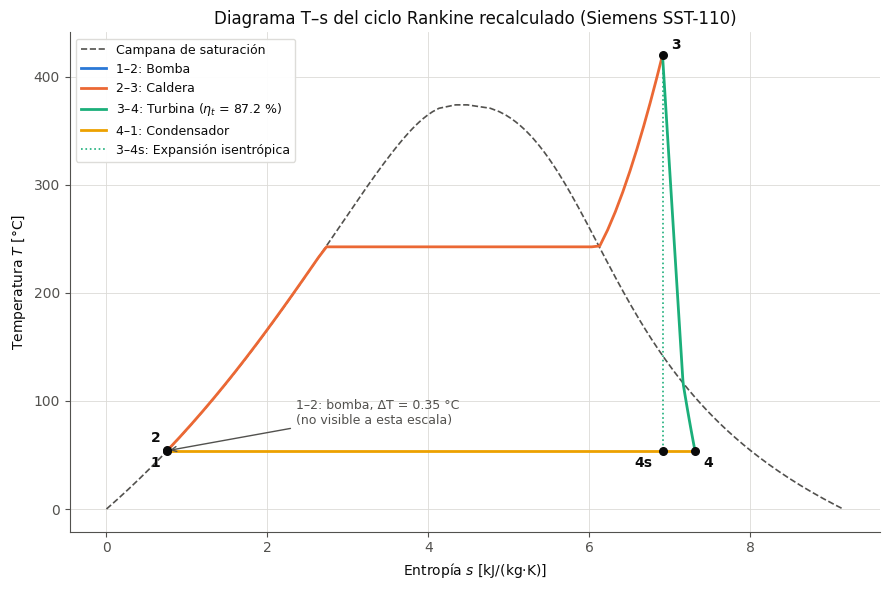

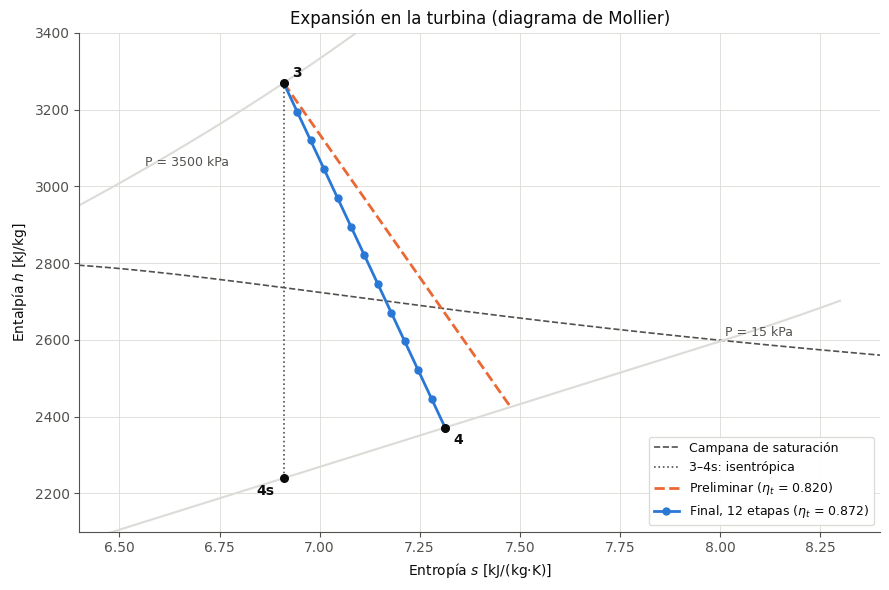

In [18]:
fig = figura_ciclo(ciclo_final, 'Diagrama T–s del ciclo Rankine recalculado (Siemens SST-110)')
fig.savefig('diagrama_Ts_rankine_recalculado.png')
plt.show()
fig = figura_expansion_hs(ciclo_preliminar, resultado)
fig.savefig('diagrama_hs_expansion.png')
plt.show()

## 6. Conclusiones

Los números de esta sección se generan a partir de los resultados, así que se actualizan solos si cambian los datos.

In [19]:
c0, cf = ciclo_preliminar['desempeno'], ciclo_final['desempeno']
tabla_o, tabla_f = diseno_original['tabla'], turbina['tabla']
parcial = tabla_f[tabla_f['admision'] < 1]
display(Markdown(rf'''
1. Con $\eta_t = {ETA_TURBINA_INICIAL}$ el ciclo preliminar da $\eta_{{th}} = {c0['eta_termica'] * 100:.2f}\,\%$
   y requiere $\dot m = {c0['flujo_masico']:.2f}\ \mathrm{{kg/s}}$.
2. El diseño anterior (6 etapas, 11 500 rpm) **no es viable**: el Mach llega a {tabla_o['Mach'].max():.2f}
   en las etapas húmedas y el primer álabe mediría {tabla_o['h_teorica [mm]'].min():.1f} mm con admisión total.
3. El diseño corregido tiene **{diseno['etapas']} etapas** de reacción 50 % a **{diseno['N_rpm']:.0f} rpm**
   con $D_m = {diseno['D_medio']:.3f}\ \mathrm{{m}}$, $u = {turbina['u']:.1f}\ \mathrm{{m/s}}$,
   $\psi = {turbina['psi']:.2f}$ y $\phi = {diseno['phi']}$. El Mach máximo es {tabla_f['Mach'].max():.2f} (< 0.8).
   Las {len(parcial)} primeras etapas usan admisión parcial (entre {parcial['admision'].min():.0%} y {parcial['admision'].max():.0%}).
4. El lazo ciclo ↔ turbina converge en {len(resultado['historial'])} iteraciones a $\eta_t = {turbina['eta_turbina'] * 100:.1f}\,\%$.
   El ciclo final tiene $\eta_{{th}} = {cf['eta_termica'] * 100:.2f}\,\%$, $\dot m = {cf['flujo_masico']:.2f}\ \mathrm{{kg/s}}$
   y $x_4 = {ciclo_final['estados']['4']['x']:.3f}$ (≥ 0.88, sin riesgo de erosión severa).
5. El punto de operación cae dentro de la envolvente de la Siemens SST-110 en presión y temperatura de admisión.
   La velocidad máxima y la presión mínima de escape del catálogo deben confirmarse con el datasheet.
'''))


1. Con $\eta_t = 0.82$ el ciclo preliminar da $\eta_{th} = 27.64\,\%$
   y requiere $\dot m = 4.17\ \mathrm{kg/s}$.
2. El diseño anterior (6 etapas, 11 500 rpm) **no es viable**: el Mach llega a 1.09
   en las etapas húmedas y el primer álabe mediría 2.0 mm con admisión total.
3. El diseño corregido tiene **12 etapas** de reacción 50 % a **8217 rpm**
   con $D_m = 0.559\ \mathrm{m}$, $u = 240.7\ \mathrm{m/s}$,
   $\psi = 1.29$ y $\phi = 0.5$. El Mach máximo es 0.77 (< 0.8).
   Las 5 primeras etapas usan admisión parcial (entre 21% y 71%).
4. El lazo ciclo ↔ turbina converge en 6 iteraciones a $\eta_t = 87.2\,\%$.
   El ciclo final tiene $\eta_{th} = 29.40\,\%$, $\dot m = 3.92\ \mathrm{kg/s}$
   y $x_4 = 0.904$ (≥ 0.88, sin riesgo de erosión severa).
5. El punto de operación cae dentro de la envolvente de la Siemens SST-110 en presión y temperatura de admisión.
   La velocidad máxima y la presión mínima de escape del catálogo deben confirmarse con el datasheet.


## 7. Limitaciones y trabajo futuro

- **Línea de expansión y trabajo por etapa.** La expansión se supone recta en $h$–$s$ y el trabajo se reparte por igual
  entre etapas. Una distribución no uniforme permitiría cargar más las etapas de alta presión, donde hay margen de Mach.
- **Admisión parcial en etapas de reacción.** En la práctica, las etapas de alta presión con admisión parcial se agrupan
  en una **etapa de control de acción** (rueda Curtis) que toma un salto entálpico grande. No se modelan las pérdidas
  por ventilación del sector inactivo.
- **Modelo de pérdidas pedagógico.** Se usan $\eta_{al}$ y la regla de Baumann. Correlaciones como Soderberg o
  Ainley–Mathieson darían una estimación más fina. Se desprecia el factor de recalentamiento, lo que es conservador.
- **Velocidad del sonido en vapor húmedo.** Se estima con el exponente de Zeuner, que es una aproximación.
- **Análisis de línea media.** Con $h/D_m = 0.3$ en la última etapa, el diseño real necesita álabes torsionados (vórtice libre).
- **Configuración del equipo.** La configuración interna de la SST-110 (doble carcasa, reductor) y los límites de
  velocidad y de presión de escape deben confirmarse con el datasheet del fabricante.
- **Potencia.** No se incluyen las eficiencias del reductor ni del generador: los 3.5 MW son potencia mecánica neta.